# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:**Shaista
- **Student ID:**023-24-0122
- **Section:**E
- **Kaggle:**https://www.kaggle.com/shaistasuleman
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)

# TotalCharges is loaded as text, convert it to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Fill missing values with the median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Drop the ID column and map the target to 0/1
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

df.head()

Shape: (7043, 21)
Missing TotalCharges: 11


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [5]:
from sklearn.model_selection import train_test_split

# One-hot encode categorical columns
df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns=["Churn"])
y = df["Churn"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(y_train.value_counts(normalize=True))

X_train: (5634, 30) | X_test: (1409, 30)
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [6]:
print([v for v in dir() if "train" in v or v in ("df", "X", "y")])

['X', 'X_train', 'df', 'train_test_split', 'y', 'y_train']


In [7]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(5634, 30) (1409, 30) (5634,) (1409,)


In [2]:
import os, time, warnings
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# Load, clean, encode, split
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns=["Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Split done:", X_train.shape, X_test.shape)

# Unscaled linear SVM with an iteration cap so it cannot hang forever
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    start = time.time()
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=200000)
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - start

y_pred_raw = svm_raw.predict(X_test)
print(f"Unscaled -> Acc: {accuracy_score(y_test, y_pred_raw):.4f} | "
      f"F1: {f1_score(y_test, y_pred_raw):.4f} | Time: {time_raw:.2f}s | Warnings: {len(w_raw)}")

Split done: (5634, 30) (1409, 30)
Unscaled -> Acc: 0.4556 | F1: 0.2413 | Time: 10.31s | Warnings: 2


In [4]:
import os, time, warnings
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Rebuild the split only if this session lost it
if "X_train" not in globals():
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
    df = df.drop(columns=["customerID"])
    df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
    df = pd.get_dummies(df, drop_first=True)
    X = df.drop(columns=["Churn"])
    y = df["Churn"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print("Split rebuilt:", X_train.shape, X_test.shape)

# Fit the scaler on TRAIN only, then transform both train and test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Train the same linear SVM on the scaled features
with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    start = time.time()
    svm_scaled = SVC(kernel="linear", random_state=42)
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.time() - start

y_pred_s = svm_scaled.predict(X_test_s)
acc_s = accuracy_score(y_test, y_pred_s)
f1_s = f1_score(y_test, y_pred_s)

print(f"Scaled -> Accuracy: {acc_s:.4f} | F1: {f1_s:.4f} | Time: {time_scaled:.2f}s | Warnings: {len(w_s)}")

Scaled -> Accuracy: 0.7892 | F1: 0.5714 | Time: 1.96s | Warnings: 0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:*The unscaled linear SVM got accuracy _ 0.4556 and F1 0.2413 in 10.03s with 2 warnings. The scaled model got accuracy 0.7892 and F1 0.5714 in 1.96 s with 0 warnings.
(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*SVM maximizes the margin using distances between points, so features with large ranges (like TotalCharges, tenure) dominate, while the 0/1 dummy columns barely matter. The boundary ends up biased toward a few large-scale features, and the optimizer converges slowly because the problem is badly scaled.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:*I will use the scaled version (StandardScaler fit on the training set only, then applied to the test set) for every later SVM. It trains faster, lets all features contribute fairly to the margin, and fitting on train only avoids data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
import time
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Rebuild the scaled split only if this session lost it
if "X_train_s" not in globals():
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
    df = df.drop(columns=["customerID"])
    df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
    df = pd.get_dummies(df, drop_first=True)
    X, y = df.drop(columns=["Churn"]), df["Churn"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

models, preds, rows = {}, {}, []
for k in ["linear", "rbf", "poly"]:
    start = time.time()
    m = SVC(kernel=k, random_state=42)
    m.fit(X_train_s, y_train)
    t = time.time() - start
    p = m.predict(X_test_s)
    models[k], preds[k] = m, p
    rows.append({
        "Kernel": k,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "Support Vectors": m.support_.shape[0],
        "Train Time (s)": round(t, 2),
    })
print("Done:", list(models))



Done: ['linear', 'rbf', 'poly']


In [6]:
results = pd.DataFrame(rows).set_index("Kernel").round(4)
results


,Accuracy,Precision,Recall,F1,Support Vectors,Train Time (s)
Kernel,,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569,3.67
rbf,0.7928,0.6444,0.4893,0.5562,2661,1.76
poly,0.7892,0.6421,0.4652,0.5395,2739,1.09


Best kernel by F1: linear


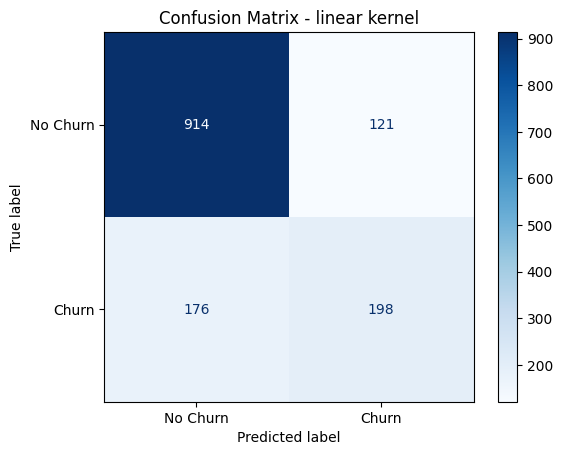

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Pick the kernel with the highest F1 from the results table
best = results["F1"].idxmax()
print("Best kernel by F1:", best)

ConfusionMatrixDisplay.from_predictions(
    y_test, preds[best], display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title(f"Confusion Matrix - {best} kernel")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:*Linear gave the best F1 (0.5714), ahead of RBF (0.5562) and poly (0.5395). This is slightly surprising, since RBF/poly are more flexible, but it suggests the churn data is close to linearly separable. The gaps are smal

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:*Poly used the most support vectors (2739, vs 2661 for RBF and 2569 for linear). A high count means many points lie on or inside the margin, so the classes overlap and the boundary is more complex.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:*I will carry RBF forward. Its F1 (0.5562) is close to linear’s, it has the best accuracy (0.7928) and precision (0.6444), and its two hyperparameters (C, gamma) give tuning more room to improve recall.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit PCA on the scaled TRAIN data only, then transform the test data
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio: [0.3325 0.1198]
Total explained variance: 0.4523


In [9]:
from sklearn.svm import SVC

# Train an RBF SVM on the 2D projection for a small, medium and large C
C_values = [0.01, 1, 100]
svms_2d = {}
for C in C_values:
    m = SVC(kernel="rbf", C=C, gamma="scale", random_state=42)
    m.fit(X_train_2d, y_train)
    svms_2d[C] = m
    print(f"C={C}: support vectors = {m.support_.shape[0]}, "
          f"train accuracy = {m.score(X_train_2d, y_train):.4f}")

C=0.01: support vectors = 2997, train accuracy = 0.7346
C=1: support vectors = 2659, train accuracy = 0.7792
C=100: support vectors = 2631, train accuracy = 0.7813


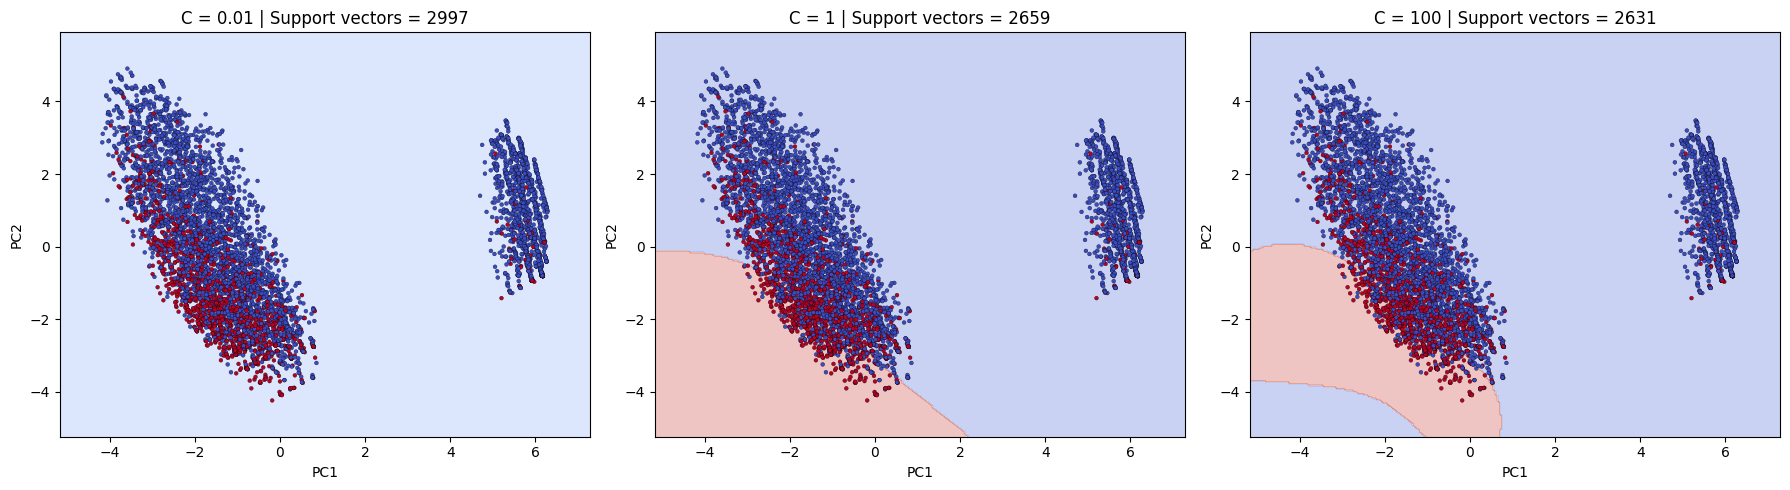

In [10]:
# Build the mesh grid slightly beyond the data range
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

# Plot the decision regions and training points for each C
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, C in zip(axes, C_values):
    m = svms_2d[C]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train,
               cmap="coolwarm", s=8, edgecolor="k", linewidth=0.2)
    ax.set_title(f"C = {C} | Support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*As C increases from 0.01 to 100, the decision boundary goes from smooth and simple [possibly almost a single region] to more irregular and wiggly, with small islands around individual points. A larger C penalizes margin violations more, so the model bends the boundary to classify more training points correctly.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [12]:
import time
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# C and gamma values spanning several orders of magnitude
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1],
}

gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid,
                  cv=5, scoring="f1", n_jobs=-1)

start = time.time()
gs.fit(X_train_s, y_train)   # scaled TRAIN data only
print(f"Grid search took {time.time() - start:.1f}s")
print("Best params:", gs.best_params_)
print("Best CV F1:", round(gs.best_score_, 4))

Grid search took 109.3s
Best params: {'C': 100, 'gamma': 0.01}
Best CV F1: 0.5877


param_gamma   0.001   0.010   0.100   1.000
param_C                                    
0.1          0.0000  0.5417  0.4640  0.0000
1.0          0.5746  0.5650  0.5734  0.3261
10.0         0.5857  0.5853  0.5266  0.3621
100.0        0.5710  0.5877  0.5060  0.3621


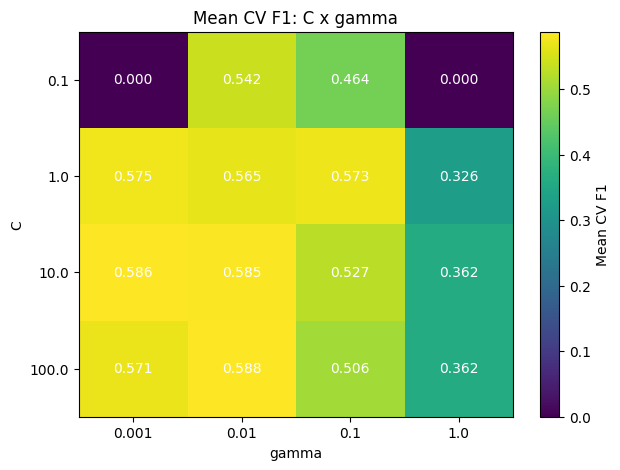

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Pivot the CV results into a C x gamma table
cv = pd.DataFrame(gs.cv_results_)
heat = cv.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
print(heat.round(4))

# Draw the heatmap with the score written in each cell
plt.figure(figsize=(7, 5))
plt.imshow(heat.values, cmap="viridis", aspect="auto")
plt.colorbar(label="Mean CV F1")
plt.xticks(range(len(heat.columns)), heat.columns)
plt.yticks(range(len(heat.index)), heat.index)
plt.xlabel("gamma")
plt.ylabel("C")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="white")
plt.title("Mean CV F1: C x gamma")
plt.show()

Best params: {'C': 100, 'gamma': 0.01}
Best CV F1    : 0.5877
Test Accuracy : 0.7786
Test Precision: 0.5939
Test Recall   : 0.5241
Test F1       : 0.5568


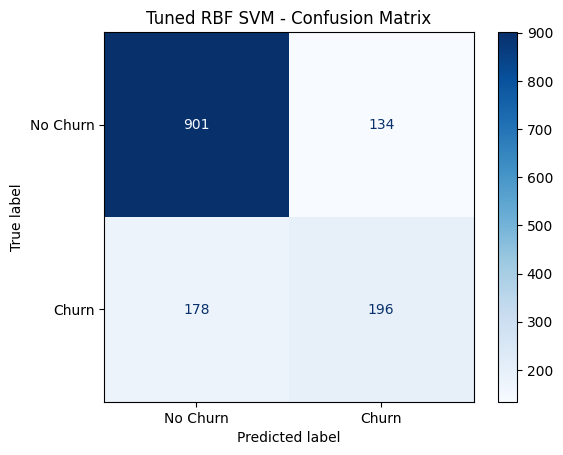

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

# GridSearchCV already refit the best model on the full training set
best_svm = gs.best_estimator_
y_pred_best = best_svm.predict(X_test_s)

print("Best params:", gs.best_params_)
print(f"Best CV F1    : {gs.best_score_:.4f}")
print(f"Test Accuracy : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Test Recall   : {recall_score(y_test, y_pred_best):.4f}")
print(f"Test F1       : {f1_score(y_test, y_pred_best):.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Tuned RBF SVM - Confusion Matrix")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*The best parameters were C = 100 and gamma = 0.01, with a cross-validated F1 of 0.5877.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*Several combinations perform almost the same. A broad good region covers C = 1 to 100 with gamma = 0.001 to 0.01, where F1 stays between 0.565 and 0.588. The best cell (0.5877) beats the next ones (0.5857, 0.5853) by only about 0.002. Gamma = 1 is clearly bad (F1 0.33 to 0.36) because it overfits, and C = 0.1 with gamma = 0.001 or 1 gives F1 = 0 because the model predicts only the majority class. So the model is not very sensitive to exact values inside the good region, but it is sensitive to extreme gamma and very small C.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*CV F1 was 0.5877 and test F1 was 0.5568, a gap of about 0.031. This is a small gap, so the model generalizes reasonably well. A large gap would suggest overfitting to the training folds or a test set that is not representative.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*Tuning was not really worth it. The tuned model’s test F1 is 0.5568, versus 0.5562 for the untuned RBF, a gain of only 0.0006. Recall improved (0.5241 vs 0.4893), but precision (0.5939 vs 0.6444) and accuracy (0.7786 vs 0.7928) both dropped. The 109 s grid search brought almost no real improvement, which suggests the default settings were already near the best this model can do on this data.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


           class_weight=None  class_weight='balanced'
Precision             0.5939                   0.5152
Recall                0.5241                   0.7701
F1                    0.5568                   0.6174


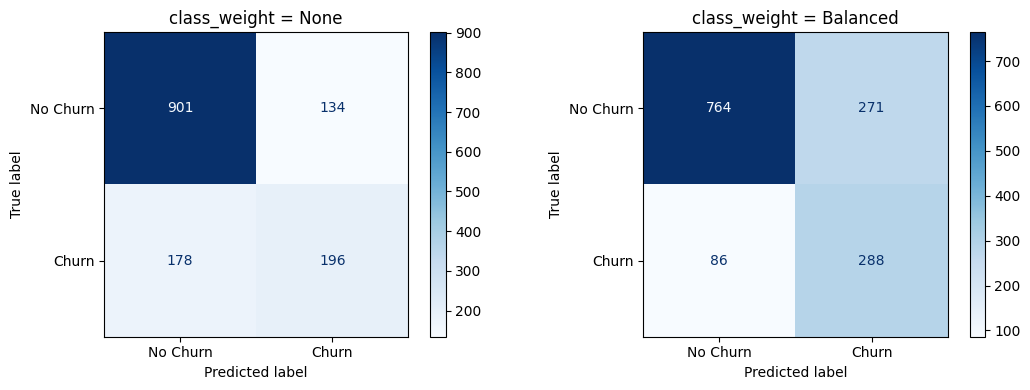

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

best_C, best_gamma = 100, 0.01   # best params from Part 4

# probability=True is needed later for ROC scores (Q5c)
svm_none = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
               class_weight=None, probability=True, random_state=42)
svm_bal = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
              class_weight="balanced", probability=True, random_state=42)
svm_none.fit(X_train_s, y_train)
svm_bal.fit(X_train_s, y_train)

pred_none = svm_none.predict(X_test_s)
pred_bal = svm_bal.predict(X_test_s)

# Metrics table
cmp = pd.DataFrame({
    "class_weight=None": [precision_score(y_test, pred_none),
                          recall_score(y_test, pred_none),
                          f1_score(y_test, pred_none)],
    "class_weight='balanced'": [precision_score(y_test, pred_bal),
                                recall_score(y_test, pred_bal),
                                f1_score(y_test, pred_bal)],
}, index=["Precision", "Recall", "F1"]).round(4)
print(cmp)

# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, p, title in zip(axes, [pred_none, pred_bal], ["None", "Balanced"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p, display_labels=["No Churn", "Churn"], cmap="Blues", ax=ax)
    ax.set_title(f"class_weight = {title}")
plt.tight_layout()
plt.show()

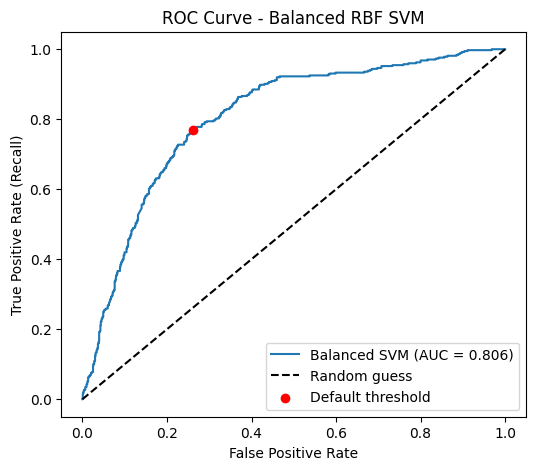

AUC: 0.8058


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Probability-like scores for the churn class (needs probability=True)
scores = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, scores)
auc = roc_auc_score(y_test, scores)

# Operating point of the default predict() decision
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Balanced SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.scatter(op_fpr, op_tpr, color="red", zorder=5, label="Default threshold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Balanced RBF SVM")
plt.legend()
plt.show()
print("AUC:", round(auc, 4))

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*With class_weight='balanced', precision dropped from 0.5939 to 0.5152, while recall rose from 0.5241 to 0.7701. F1 also improved, from 0.5568 to 0.6174.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*Missing a churner costs more, because the company loses all that customer’s future revenue, while a false alarm only wastes a small offer. I would deploy the balanced model, since its recall (0.7701) and F1 (0.6174) are both higher.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*I had to set probability=True in SVC(), which enables predict_proba for the ROC curve.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [17]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

results_all = {}

# Tree-based models do not need scaling
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
results_all["Decision Tree"] = scores(y_test, dt.predict(X_test))

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)
results_all["Random Forest"] = scores(y_test, rf.predict(X_test))

# Logistic Regression and KNN use the scaled data
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
results_all["Logistic Regression"] = scores(y_test, lr.predict(X_test_s))

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
results_all["KNN"] = scores(y_test, knn.predict(X_test_s))

# Best SVM from Part 5 (tuned RBF, class_weight='balanced')
results_all["SVM (tuned, balanced)"] = scores(y_test, pred_bal)

comparison = pd.DataFrame(results_all).T.round(4)
comparison

,Accuracy,Precision,Recall,F1
Decision Tree,0.7417,0.5139,0.4947,0.5041
Random Forest,0.7899,0.6336,0.4947,0.5556
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN,0.7473,0.5253,0.5000,0.5123
"SVM (tuned, balanced)",0.7466,0.5152,0.7701,0.6174


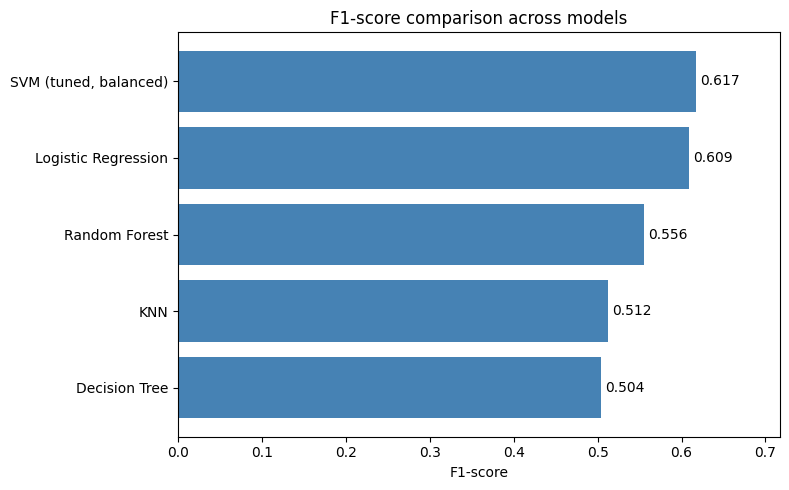

In [18]:
import matplotlib.pyplot as plt

# Sort models by F1 so the best one is at the top
f1_sorted = comparison["F1"].sort_values()

plt.figure(figsize=(8, 5))
bars = plt.barh(f1_sorted.index, f1_sorted.values, color="steelblue")
for bar, v in zip(bars, f1_sorted.values):
    plt.text(v + 0.005, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center")
plt.xlabel("F1-score")
plt.title("F1-score comparison across models")
plt.xlim(0, max(f1_sorted.values) + 0.1)
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*The tuned balanced SVM wins on F1 (0.6174), narrowly ahead of Logistic Regression (0.6092). The SVM also wins on recall (0.7701, next best is Logistic Regression at 0.5668). So the same model wins both.
*Your answer:*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*Only partly. The SVM took much longer (109 s for the grid search alone, plus slower training with probability=True), while Decision Tree and Random Forest train in a few seconds. Its F1 is only 0.0082 above Logistic Regression’s, which is cheap and fast. But its recall is far higher (0.7701 vs 0.5668), which matters for catching churners. So the cost is worth it only if recall is the priority

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:*I would deploy the tuned balanced SVM. It has the highest recall (0.7701) and the highest F1 (0.6174), so it catches the most churners. The price is the lowest precision (0.5152) and lower accuracy (0.7466 vs 0.8070 for Logistic Regression), which is acceptable because missing a churner costs more than a false alarm. Logistic Regression is a strong, simpler alternative if precision and accuracy matter more.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [19]:
import pandas as pd

# Predictions and churn probability from the final model (tuned balanced SVM)
final_model = svm_bal
pred_final = final_model.predict(X_test_s)
churn_prob = final_model.predict_proba(X_test_s)[:, 1]

out = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": pred_final,
    "churn_probability": churn_prob.round(4),
})
out.to_csv("svm_predictions.csv", index=False)
print("Saved svm_predictions.csv with", len(out), "rows")
out.head()

Saved svm_predictions.csv with 1409 rows


,true_label,predicted_label,churn_probability
0,0,0,0.0606
1,0,1,0.6042
2,0,0,0.0402
3,0,0,0.2548
4,0,0,0.0390


**Executive Summary**

*Your summary here.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*The most surprising result was that tuning C and gamma barely helped (test F1 0.5568 vs 0.5562 untuned), while class_weight='balanced' raised recall from 0.5241 to 0.7701.

(b) If you had one more hour, what would you try next?

*Your answer:*With one more hour I would apply balanced class weights to the other models for a fair comparison, tune the decision threshold, and try SMOTE for the imbalance
